![MuJoCo banner](https://raw.githubusercontent.com/google-deepmind/mujoco/main/banner.png)

# <h1><center>Model Editing  <a href="https://colab.research.google.com/github/google-deepmind/mujoco/blob/main/python/mjspec.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" width="140" align="center"/></a></center></h1>

This notebook provides an introductory tutorial for model editing in MuJoCo using the `mjSpec` API. This notebook assumes that the reader is already familiar with MuJoCo basic concepts, as
demonstrated in the [introductory tutorial](https://github.com/google-deepmind/mujoco?tab=readme-ov-file#getting-started). Documentation for this API can be found in the [Model Editing](https://mujoco.readthedocs.io/en/latest/programming/modeledit.html) chapter in the documentation (C API) and in the [Python chapter](https://mujoco.readthedocs.io/en/latest/python.html#model-editing). Here we use the Python API.

The goal of the API is to allow users to easily interact with and modify MuJoCo
models in Python, similarly to what the JavaScript DOM does for HTML.

<!-- Copyright 2024 DeepMind Technologies Limited

     Licensed under the Apache License, Version 2.0 (the "License");
     you may not use this file except in compliance with the License.
     You may obtain a copy of the License at

         http://www.apache.org/licenses/LICENSE-2.0

     Unless required by applicable law or agreed to in writing, software
     distributed under the License is distributed on an "AS IS" BASIS,
     WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
     See the License for the specific language governing permissions and
     limitations under the License.
-->


## All imports

In [1]:
!pip install mujoco

# Set up GPU rendering.
from google.colab import files
import distutils.util
import os
import subprocess
if subprocess.run('nvidia-smi').returncode:
  raise RuntimeError(
      'Cannot communicate with GPU. '
      'Make sure you are using a GPU Colab runtime. '
      'Go to the Runtime menu and select Choose runtime type.')

# Add an ICD config so that glvnd can pick up the Nvidia EGL driver.
# This is usually installed as part of an Nvidia driver package, but the Colab
# kernel doesn't install its driver via APT, and as a result the ICD is missing.
# (https://github.com/NVIDIA/libglvnd/blob/master/src/EGL/icd_enumeration.md)
NVIDIA_ICD_CONFIG_PATH = '/usr/share/glvnd/egl_vendor.d/10_nvidia.json'
if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
  with open(NVIDIA_ICD_CONFIG_PATH, 'w') as f:
    f.write("""{
    "file_format_version" : "1.0.0",
    "ICD" : {
        "library_path" : "libEGL_nvidia.so.0"
    }
}
""")

# Configure MuJoCo to use the EGL rendering backend (requires GPU)
print('Setting environment variable to use GPU rendering:')
%env MUJOCO_GL=egl

# Check if installation was successful.
try:
  print('Checking that the installation succeeded:')
  import mujoco as mj
  mj.MjModel.from_xml_string('<mujoco/>')
except Exception as e:
  raise e from RuntimeError(
      'Something went wrong during installation. Check the shell output above '
      'for more information.\n'
      'If using a hosted Colab runtime, make sure you enable GPU acceleration '
      'by going to the Runtime menu and selecting "Choose runtime type".')

print('Installation successful.')

# Other imports and helper functions
import numpy as np
import random
from scipy.signal import convolve2d

# Graphics and plotting.
print('Installing mediapy:')
!command -v ffmpeg >/dev/null || (apt update && apt install -y ffmpeg)
!pip install -q mediapy
import mediapy as media
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Printing.
np.set_printoptions(precision=3, suppress=True, linewidth=100)
import pygments
from google.colab import output

from IPython.display import clear_output, HTML, display
clear_output()


is_dark = output.eval_js('document.documentElement.matches("[theme=dark]")')
print_style = 'monokai' if is_dark else 'lovelace'

def print_xml(xml_string):
  formatter = pygments.formatters.HtmlFormatter(style=print_style)
  lexer = pygments.lexers.XmlLexer()
  highlighted = pygments.highlight(xml_string, lexer, formatter)
  display(HTML(f"<style>{formatter.get_style_defs()}</style>{highlighted}"))

def render(model, data=None, height=300, camera=-1):
  if data is None:
    data = mj.MjData(model)
  with mj.Renderer(model, 480, 640) as renderer:
    mj.mj_forward(model, data)
    renderer.update_scene(data, camera)
    media.show_image(renderer.render(), height=height)

# Separate parsing and compiling

Unlike `mj_loadXML` which combines parsing and compiling, when using `mjSpec`, parsing and compiling are separate, allowing for editing steps:


""

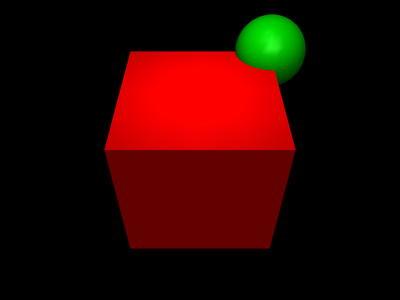

""

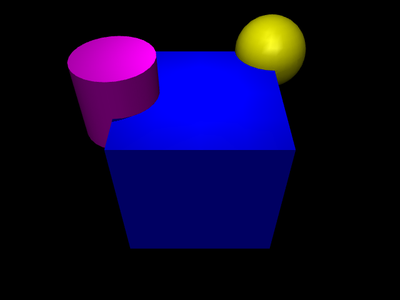

In [2]:
#@title Parse, compile, modify, compile: {vertical-output: true}

static_model = """
<mujoco>
  <worldbody>
    <light name="top" pos="0 0 1"/>
    <geom name="red_box" type="box" size=".2 .2 .2" rgba="1 0 0 1"/>
    <geom name="green_sphere" pos=".2 .2 .2" size=".1" rgba="0 1 0 1"/>
  </worldbody>
</mujoco>
"""
spec = mj.MjSpec.from_string(static_model)
model = spec.compile()
render(model)

# Change the mjSpec, re-compile and re-render
spec.modelname = "edited model"
geoms = spec.worldbody.find_all(mj.mjtObj.mjOBJ_GEOM)
geoms[0].name = 'blue_box'
geoms[0].rgba = [0, 0, 1, 1]
geoms[1].name = 'yellow_sphere'
geoms[1].rgba = [1, 1, 0, 1]
spec.worldbody.add_geom(name='magenta cylinder',
                        type=mj.mjtGeom.mjGEOM_CYLINDER,
                        rgba=[1, 0, 1, 1],
                        pos=[-.2, 0, .2],
                        size=[.1, .1, 0])

model = spec.compile()
render(model)

`mjSpec` can save XML to string, with all modifications:

In [3]:
print_xml(spec.to_xml())

# Procedural models

In [4]:
#@title {vertical-output: true}

spec = mj.MjSpec()
spec.worldbody.add_light(name="top", pos=[0, 0, 1])
body = spec.worldbody.add_body(name="box_and_sphere",
                               euler=[0, 0, -30])
body.add_joint(name="swing", type=mj.mjtJoint.mjJNT_HINGE,
               axis=[1, -1, 0], pos=[-.2, -.2, -.2])
body.add_geom(name="red_box", type=mj.mjtGeom.mjGEOM_BOX,
              size=[.2, .2, .2], rgba=[1, 0, 0, 1])
body.add_geom(name="green_sphere", pos=[.2, .2, .2],
              size=[.1, 0, 0], rgba=[0, 1, 0, 1])
model = spec.compile()

duration = 2    # (seconds)
framerate = 30  # (Hz)

# enable joint visualization option:
scene_option = mj.MjvOption()
scene_option.flags[mj.mjtVisFlag.mjVIS_JOINT] = True

# Simulate and display video.
frames = []
data = mj.MjData(model)
mj.mj_resetData(model, data)
with mj.Renderer(model) as renderer:
  while data.time < duration:
    mj.mj_step(model, data)
    if len(frames) < data.time * framerate:
      renderer.update_scene(data, scene_option=scene_option)
      pixels = renderer.render()
      frames.append(pixels)

media.show_video(frames, fps=framerate)

This browser does not support the video tag.


## Tree

Let's use procedural model creation to make a simple model of a tree.

We'll start with an "arena" xml, containing only a plane and light, and define some utility functions.

In [5]:
#@title Utilities
def branch_frames(num_samples, phi_lower=np.pi / 8, phi_upper=np.pi / 3):
  """Returns branch direction vectors and normalized attachment heights."""
  directions = []
  theta_slice = (2 * np.pi) / num_samples
  phi_slice = (phi_upper - phi_lower) / num_samples
  for i in range(num_samples):
    theta = np.random.uniform(i * theta_slice, (i + 1) * theta_slice)
    phi = phi_lower + np.random.uniform(i * phi_slice, (i + 1) * phi_slice)
    x = np.sin(phi) * np.cos(theta)
    y = np.sin(phi) * np.sin(theta)
    z = np.cos(phi)
    directions.append([x, y, z])

  heights = np.linspace(0.6, 1, num_samples)

  return directions, heights


def add_arrow(scene, from_, to, radius=0.03, rgba=[0.2, 0.2, 0.6, 1]):
  """Add an arrow to the scene."""
  scene.geoms[scene.ngeom].category = mj.mjtCatBit.mjCAT_STATIC
  mj.mjv_initGeom(
      geom=scene.geoms[scene.ngeom],
      type=mj.mjtGeom.mjGEOM_ARROW,
      size=np.zeros(3),
      pos=np.zeros(3),
      mat=np.zeros(9),
      rgba=np.asarray(rgba).astype(np.float32),
  )
  mj.mjv_connector(
      geom=scene.geoms[scene.ngeom],
      type=mj.mjtGeom.mjGEOM_ARROW,
      width=radius,
      from_=from_,
      to=to,
  )
  scene.ngeom += 1


def unit_bump(x, start, end):
  """Finite-support unit bump function."""
  if x <= start or x >= end:
    return 0.0
  else:
    n = (x - start) / (end - start)
    n = 2 * n - 1
    return np.exp(n * n / (n * n - 1))

Our tree creation function is called recursively to add branches and leaves.

In [6]:
# @title Tree creation
def procedural_tree(
    num_child_branch=5,
    length=0.5,
    thickness=0.04,
    depth=4,
    this_body=None,
    spec=None,
):
  """Recursive function that builds a tree of branches and leaves."""
  BROWN = np.array([0.4, 0.24, 0.0, 1])
  GREEN = np.array([0.0, 0.7, 0.2, 1])
  SCALE = 0.6

  # Initialize spec and add tree trunk
  if this_body is None:
    if spec is None:
      spec = mj.MjSpec()

    # Disable constraints
    spec.option.disableflags |= mj.mjtDisableBit.mjDSBL_CONSTRAINT

    # Air density
    spec.option.density = 1.294

    # Defaults for joint and geom
    main = spec.default
    main.geom.type = mj.mjtGeom.mjGEOM_CAPSULE
    main.joint.type = mj.mjtJoint.mjJNT_BALL
    main.joint.springdamper = [0.003, 0.7]

    # Visual
    spec.stat.center = [0, 0, length]
    spec.stat.extent = 2 * length

    # Add trunk body
    this_body = spec.worldbody.add_body(name="trunk")
    fromto = [0, 0, 0, 0, 0, length]
    size = [thickness, 0, 0]
    this_body.add_geom(fromto=fromto, size=size, rgba=BROWN)

  # Sample a random color
  rgba = np.random.uniform(size=4)
  rgba[3] = 1

  # Add child branches using recursive call
  if depth > 0:
    # Get branch direction vectors and attachment heights
    dirs, heights = branch_frames(num_child_branch)
    heights *= length

    # Rescale branches with some randomness
    thickness *= SCALE * np.random.uniform(0.9, 1.1)
    length *= SCALE * np.random.uniform(0.9, 1.1)

    # Branch creation
    for i in range(num_child_branch):
      branch = this_body.add_body(pos=[0, 0, heights[i]], zaxis=dirs[i])

      fromto = [0, 0, 0, 0, 0, length]
      size = [thickness, 0, 0]
      rgba = (rgba + BROWN) / 2
      branch.add_geom(fromto=fromto, size=size, rgba=rgba)

      branch.add_joint()

      # Recurse.
      procedural_tree(
          length=length,
          thickness=thickness,
          depth=depth - 1,
          this_body=branch,
          spec=spec,
      )

  # Max depth reached, add three leaves at the tip
  else:
    rgba = (rgba + GREEN) / 2
    for i in range(3):
      pos = [0, 0, length + thickness]
      euler = [0, 0, i * 120]
      leaf_frame = this_body.add_frame(pos=pos, euler=euler)

      size = length * np.array([0.5, 0.15, 0.01])
      pos = length * np.array([0.45, 0, 0])
      ellipsoid = mj.mjtGeom.mjGEOM_ELLIPSOID
      euler = [np.random.uniform(-50, 50), 0, 0]
      leaf = this_body.add_geom(
          type=ellipsoid, size=size, pos=pos, rgba=rgba, euler=euler
      )

      leaf.set_frame(leaf_frame)

  return spec

In [7]:
#@title Make video
arena_xml = """
<mujoco>
  <visual>
    <headlight diffuse=".5 .5 .5" specular="1 1 1"/>
    <global elevation="-10" offwidth="2048" offheight="1536"/>
    <quality shadowsize="8192"/>
  </visual>

  <asset>
    <texture type="skybox" builtin="gradient" rgb1=".5 .5 .5" rgb2="0 0 0" width="10" height="10"/>
    <texture type="2d" name="groundplane" builtin="checker" mark="edge" rgb1="1 1 1" rgb2="1 1 1" markrgb="0 0 0" width="300" height="300"/>
    <material name="groundplane" texture="groundplane" texuniform="true" texrepeat="5 5" reflectance="0.3"/>
  </asset>

  <worldbody>
    <geom name="floor" size="5 5 0.01" type="plane" material="groundplane"/>
    <light pos="0 0 3" diffuse="1 1 1" specular="1 1 1"/>
  </worldbody>
</mujoco>
"""

spec = procedural_tree(spec=mj.MjSpec.from_string(arena_xml))
model = spec.compile()
data = mj.MjData(model)

duration = 3  # (seconds)
framerate = 60  # (Hz)
frames = []
with mj.Renderer(model, width=1920 // 3, height=1080 // 3) as renderer:
  while data.time < duration:
    # Add rightward wind.
    wind = 40 * unit_bump(data.time, .2 * duration, .7 * duration)
    model.opt.wind[0] = wind

    # Step and render.
    mj.mj_step(model, data)
    if len(frames) < data.time * framerate:
      renderer.update_scene(data)
      if wind > 0:
        add_arrow(renderer.scene, [0, 0, 1], [wind/25, 0, 1])
      pixels = renderer.render()
      frames.append(pixels)

media.show_video(frames, fps=framerate / 2)

This browser does not support the video tag.


## Height field

Height fields represent uneven terrain. There are many ways to generate procedural terrain. Here, we will use [Perlin Noise](https://www.youtube.com/watch?v=9x6NvGkxXhU).

### Utilities

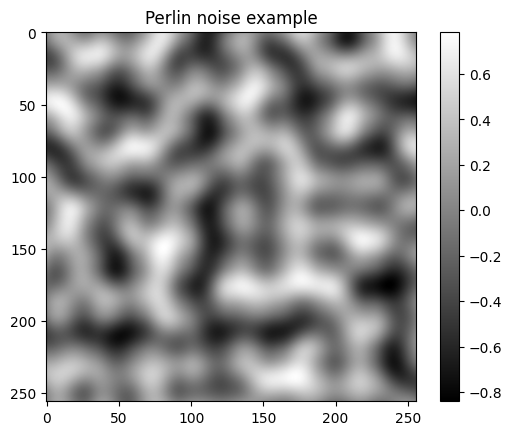

In [8]:
#@title Perlin noise generator

# adapted from https://github.com/pvigier/perlin-numpy

def interpolant(t):
    return t*t*t*(t*(t*6 - 15) + 10)

def perlin(shape, res, tileable=(False, False), interpolant=interpolant):
  """Generate a 2D numpy array of perlin noise.

  Args:
      shape: The shape of the generated array (tuple of two ints).
          This must be a multiple of res.
      res: The number of periods of noise to generate along each
          axis (tuple of two ints). Note shape must be a multiple of
          res.
      tileable: If the noise should be tileable along each axis
          (tuple of two bools). Defaults to (False, False).
      interpolant: The interpolation function, defaults to
          t*t*t*(t*(t*6 - 15) + 10).

  Returns:
      A numpy array of shape shape with the generated noise.

  Raises:
      ValueError: If shape is not a multiple of res.
  """
  delta = (res[0] / shape[0], res[1] / shape[1])
  d = (shape[0] // res[0], shape[1] // res[1])
  grid = np.mgrid[0:res[0]:delta[0], 0:res[1]:delta[1]]\
            .transpose(1, 2, 0) % 1
  # Gradients
  angles = 2*np.pi*np.random.rand(res[0]+1, res[1]+1)
  gradients = np.dstack((np.cos(angles), np.sin(angles)))
  if tileable[0]:
    gradients[-1,:] = gradients[0,:]
  if tileable[1]:
    gradients[:,-1] = gradients[:,0]
  gradients = gradients.repeat(d[0], 0).repeat(d[1], 1)
  g00 = gradients[    :-d[0],    :-d[1]]
  g10 = gradients[d[0]:     ,    :-d[1]]
  g01 = gradients[    :-d[0],d[1]:     ]
  g11 = gradients[d[0]:     ,d[1]:     ]
  # Ramps
  n00 = np.sum(np.dstack((grid[:,:,0]  , grid[:,:,1]  )) * g00, 2)
  n10 = np.sum(np.dstack((grid[:,:,0]-1, grid[:,:,1]  )) * g10, 2)
  n01 = np.sum(np.dstack((grid[:,:,0]  , grid[:,:,1]-1)) * g01, 2)
  n11 = np.sum(np.dstack((grid[:,:,0]-1, grid[:,:,1]-1)) * g11, 2)
  # Interpolation
  t = interpolant(grid)
  n0 = n00*(1-t[:,:,0]) + t[:,:,0]*n10
  n1 = n01*(1-t[:,:,0]) + t[:,:,0]*n11
  return np.sqrt(2)*((1-t[:,:,1])*n0 + t[:,:,1]*n1)

noise = perlin((256, 256), (8, 8))
plt.imshow(noise, cmap = 'gray', interpolation = 'lanczos')
plt.title('Perlin noise example')
plt.colorbar();

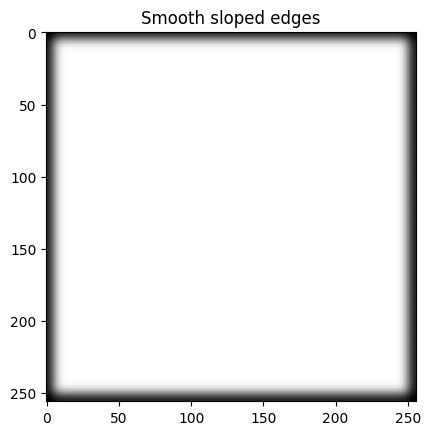

In [9]:
#@title Soft edge slope
def edge_slope(size, border_width=5, blur_iterations=20):
  """Creates a grayscale image with a white center and fading black edges using convolution."""
  img = np.ones((size, size), dtype=np.float32)
  img[:border_width, :] = 0
  img[-border_width:, :] = 0
  img[:, :border_width] = 0
  img[:, -border_width:] = 0

  kernel = np.array([[1, 1, 1],
                      [1, 1, 1],
                      [1, 1, 1]]) / 9.0

  for _ in range(blur_iterations):
    img = convolve2d(img, kernel, mode='same', boundary='symm')

  return img

image = edge_slope(256)
plt.imshow(image, cmap='gray')
plt.title('Smooth sloped edges')
plt.show()

### Textured height-field generator

In [10]:
def add_hfield(spec=None, hsize=10, vsize=4):
  """ Function that adds a height field with contours"""

  # Initialize spec
  if spec is None:
    spec = mj.MjSpec()

  # Generate Perlin noise
  size = 128
  noise = perlin((size, size), (8, 8))

  # Remap noise to 0 to 1
  noise = (noise + 1)/2
  noise -= np.min(noise)
  noise /= np.max(noise)

  # Makes the edges slope down to avoid sharp boundary
  noise *= edge_slope(size)

  # Create height field
  hfield = spec.add_hfield(name ='hfield',
                           size = [hsize, hsize, vsize, vsize/10],
                           nrow = noise.shape[0],
                           ncol = noise.shape[1],
                           userdata = noise.flatten())

  # Add texture
  texture = spec.add_texture(name = "contours",
                             type = mj.mjtTexture.mjTEXTURE_2D,
                             width = 128, height = 128)

  # Create texture map, assign to texture
  h = noise
  s = 0.7 * np.ones(h.shape)
  v = 0.7 * np.ones(h.shape)
  hsv = np.stack([h, s, v], axis=-1)
  rgb = mcolors.hsv_to_rgb(hsv)
  rgb = np.flipud((rgb * 255).astype(np.uint8))
  texture.data = rgb.tobytes()

  # Assign texture to material
  grid = spec.add_material( name = 'contours')
  grid.textures[mj.mjtTextureRole.mjTEXROLE_RGB] = 'contours'
  spec.worldbody.add_geom(type = mj.mjtGeom.mjGEOM_HFIELD,
                          material = 'contours', hfieldname = 'hfield')

  return spec

In [11]:
#@title Video

arena_xml = """
<mujoco>
  <visual>
    <headlight diffuse=".5 .5 .5" specular="1 1 1"/>
    <global offwidth="2048" offheight="1536"/>
    <quality shadowsize="8192"/>
  </visual>

  <asset>
    <texture type="skybox" builtin="gradient" rgb1="1 1 1" rgb2="1 1 1" width="10" height="10"/>
    <texture type="2d" name="groundplane" builtin="checker" mark="edge" rgb1="1 1 1" rgb2="1 1 1" markrgb="0 0 0" width="400" height="400"/>
    <material name="groundplane" texture="groundplane" texrepeat="45 45" reflectance="0"/>
  </asset>

  <worldbody>
    <geom name="floor" size="150 150 0.1" type="plane" material="groundplane"/>
  </worldbody>
</mujoco>
"""

spec = add_hfield(mj.MjSpec.from_string(arena_xml))

# Add lights
for x in [-15, 15]:
  for y in [-15, 15]:
    spec.worldbody.add_light(pos = [x, y, 10], dir = [-x, -y, -15])

# Add balls
for x in np.linspace(-8, 8, 8):
  for y in np.linspace(-8, 8, 8):
    pos = [x, y, 4 + np.random.uniform(0, 10)]
    ball = spec.worldbody.add_body(pos=pos)
    ball.add_geom(type = mj.mjtGeom.mjGEOM_SPHERE, size = [0.5, 0, 0],
                  rgba = [np.random.uniform()]*3 + [1])
    ball.add_freejoint()

model = spec.compile()
data = mj.MjData(model)

cam = mj.MjvCamera()
mj.mjv_defaultCamera(cam)
cam.lookat = [0, 0, 0]
cam.distance = 30
cam.elevation = -30

duration = 6  # (seconds)
framerate = 60  # (Hz)
frames = []
with mj.Renderer(model, width=1920 // 3, height=1080 // 3) as renderer:
  while data.time < duration:
    mj.mj_step(model, data)
    if len(frames) < data.time * framerate:
      cam.azimuth = 20 + 20 * (1 - np.cos(np.pi*data.time / duration))
      renderer.update_scene(data, cam)
      pixels = renderer.render()
      frames.append(pixels)

media.show_video(frames, fps=framerate )

This browser does not support the video tag.


## Mesh

Random meshes can be easily created by sampling random vertices on the unit sphere and letting MuJoCo create the corresponding convex hull.

In [12]:
#@title Add "rock" mesh
def add_rock(spec=None, scale=1, name="rock", pos=[0, 0, 0]):
  if spec is None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.mesh.scale = np.array([scale]*3 , dtype = np.float64)
  main.geom.type = mj.mjtGeom.mjGEOM_MESH

  # Random gray-brown color
  gray = np.array([.5, .5, .5, 1])
  light_brown = np.array([200, 150, 100, 255]) / 255.0
  mix = np.random.uniform()
  rgba = light_brown*mix + gray*(1-mix)

  # Create mesh vertices
  mesh = np.random.normal(size = (20, 3))
  mesh /= np.linalg.norm(mesh, axis=1, keepdims=True)

  # Create Body and add mesh to the Geom of the Body
  spec.add_mesh(name=name, uservert=mesh.flatten())
  body = spec.worldbody.add_body(pos=pos, name=name, mass=1)
  body.add_geom(meshname=name, rgba=rgba)
  body.add_freejoint()

  return body

In [13]:
#@title Video
spec = add_hfield(mj.MjSpec.from_string(arena_xml))

# Add lights
for x in [-15, 15]:
  for y in [-15, 15]:
    spec.worldbody.add_light(pos = [x, y, 10], dir = [-x, -y, -15])

# Add rocks
for x in np.linspace(-8, 8, 8):
  for y in np.linspace(-8, 8, 8):
    pos = [x, y, np.random.uniform(4, 14)]
    rock = add_rock(spec = spec,
                      scale = np.random.uniform(.3, 1),
                      name = f"rock_{x}_{y}",
                      pos = pos)
model = spec.compile()
data = mj.MjData(model)

cam = mj.MjvCamera()
mj.mjv_defaultCamera(cam)
cam.lookat = [0, 0, 0]
cam.distance = 30
cam.elevation = -30

duration = 6  # (seconds)
framerate = 60  # (Hz)
frames = []
with mj.Renderer(model, width=1920 // 3, height=1080 // 3) as renderer:
  while data.time < duration:
    mj.mj_step(model, data)
    if len(frames) < data.time * framerate:
      cam.azimuth = 20 + 20 * (1 - np.cos(np.pi*data.time / duration))
      renderer.update_scene(data, cam)
      pixels = renderer.render()
      frames.append(pixels)

media.show_video(frames, fps=framerate )

This browser does not support the video tag.


## Terrain Generation
Here we will create a terrain out of different tiles. We start by creating each sinlge tile. Then we move on to putting tiles side by side to create a complete terrain.

In [14]:
#@title Utilities
def render_tile(tile_func, direction=None, cam_distance=6, cam_elevation=-30):
  arena_xml = """
  <mujoco>
    <visual>
      <headlight diffuse=".5 .5 .5" specular="1 1 1"/>
      <global elevation="-10" offwidth="2048" offheight="1536"/>
      <quality shadowsize="8192"/>
    </visual>

    <asset>
      <texture type="skybox" builtin="gradient" rgb1=".5 .5 .5" rgb2="0 0 0" width="10" height="10"/>
      <texture type="2d" name="groundplane" builtin="checker" mark="edge" rgb1="1 1 1" rgb2="1 1 1" markrgb="0 0 0" width="300" height="300"/>
      <material name="groundplane" texture="groundplane" texuniform="true" texrepeat="5 5" reflectance="0.3"/>
    </asset>

    <worldbody>
      <light pos="0 0 5" diffuse="1 1 1" specular="1 1 1"/>
    </worldbody>
  </mujoco>
  """

  spec = mj.MjSpec.from_string(arena_xml)
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX

  name = 'base_tile'

  spec.worldbody.add_body(pos=[-3, 0, 0], name=name)
  if direction:
    tile_func(spec, direction=direction)
  else:
    tile_func(spec)

  model = spec.compile()
  data = mj.MjData(model)

  cam = mj.MjvCamera()
  mj.mjv_defaultCamera(cam)
  cam.lookat = [0, 0, 0]
  cam.distance = cam_distance
  cam.elevation = cam_elevation

  height = 300

  with mj.Renderer(model, 480, 640) as renderer:
    mj.mj_forward(model, data)
    renderer.update_scene(data,cam)
    media.show_image(renderer.render(), height=height)


def interpolant(t):
    return t*t*t*(t*(t*6 - 15) + 10)

def perlin(shape, res, tileable=(False, False), interpolant=interpolant):
  """Generate a 2D numpy array of perlin noise.

  Args:
      shape: The shape of the generated array (tuple of two ints).
          This must be a multiple of res.
      res: The number of periods of noise to generate along each
          axis (tuple of two ints). Note shape must be a multiple of
          res.
      tileable: If the noise should be tileable along each axis
          (tuple of two bools). Defaults to (False, False).
      interpolant: The interpolation function, defaults to
          t*t*t*(t*(t*6 - 15) + 10).

  Returns:
      A numpy array of shape shape with the generated noise.

  Raises:
      ValueError: If shape is not a multiple of res.
  """
  delta = (res[0] / shape[0], res[1] / shape[1])
  d = (shape[0] // res[0], shape[1] // res[1])
  grid = np.mgrid[0:res[0]:delta[0], 0:res[1]:delta[1]]\
            .transpose(1, 2, 0) % 1
  # Gradients
  angles = 2*np.pi*np.random.rand(res[0]+1, res[1]+1)
  gradients = np.dstack((np.cos(angles), np.sin(angles)))
  if tileable[0]:
    gradients[-1,:] = gradients[0,:]
  if tileable[1]:
    gradients[:,-1] = gradients[:,0]
  gradients = gradients.repeat(d[0], 0).repeat(d[1], 1)
  g00 = gradients[    :-d[0],    :-d[1]]
  g10 = gradients[d[0]:     ,    :-d[1]]
  g01 = gradients[    :-d[0],d[1]:     ]
  g11 = gradients[d[0]:     ,d[1]:     ]
  # Ramps
  n00 = np.sum(np.dstack((grid[:,:,0]  , grid[:,:,1]  )) * g00, 2)
  n10 = np.sum(np.dstack((grid[:,:,0]-1, grid[:,:,1]  )) * g10, 2)
  n01 = np.sum(np.dstack((grid[:,:,0]  , grid[:,:,1]-1)) * g01, 2)
  n11 = np.sum(np.dstack((grid[:,:,0]-1, grid[:,:,1]-1)) * g11, 2)
  # Interpolation
  t = interpolant(grid)
  n0 = n00*(1-t[:,:,0]) + t[:,:,0]*n10
  n1 = n01*(1-t[:,:,0]) + t[:,:,0]*n11
  return np.sqrt(2)*((1-t[:,:,1])*n0 + t[:,:,1]*n1)

def edge_slope(size, border_width=5, blur_iterations=20):
  """Creates a grayscale image with a white center and fading black edges using convolution."""
  img = np.ones((size, size), dtype=np.float32)
  img[:border_width, :] = 0
  img[-border_width:, :] = 0
  img[:, :border_width] = 0
  img[:, -border_width:] = 0

  kernel = np.array([[1, 1, 1],
                      [1, 1, 1],
                      [1, 1, 1]]) / 9.0

  for _ in range(blur_iterations):
    img = convolve2d(img, kernel, mode='same', boundary='symm')

  return img

""

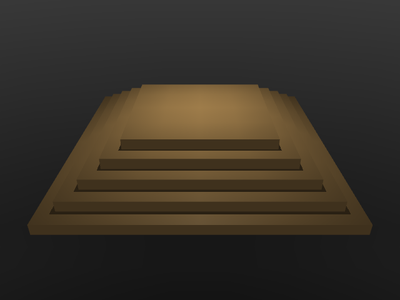

In [15]:
# @title Stairs
def stairs(spec=None, grid_loc=[0, 0] , num_stairs=4, direction=1, name='stair'):
  SQUARE_LENGTH = 2
  V_SIZE = 0.076
  H_SIZE = 0.12
  H_STEP = H_SIZE * 2
  V_STEP = V_SIZE * 2
  BROWN = [0.460, 0.362, 0.216, 1.0]

  if spec == None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX

  body = spec.worldbody.add_body(pos=grid_loc + [0], name=name)
  # Offset
  x_beginning, y_end = [-SQUARE_LENGTH + H_SIZE] * 2
  x_end, y_beginning = [SQUARE_LENGTH - H_SIZE] * 2
  # Dimension
  size_one = [H_SIZE, SQUARE_LENGTH, V_SIZE]
  size_two =  [SQUARE_LENGTH, H_SIZE, V_SIZE]
  # Geoms positions
  x_pos_l = [x_beginning, 0, direction * V_SIZE]
  x_pos_r = [x_end, 0, direction * V_SIZE]
  y_pos_up = [0, y_beginning, direction * V_SIZE]
  y_pos_down = [0, y_end, direction * V_SIZE]

  for i in range(num_stairs):
    size_one[1] = SQUARE_LENGTH - H_STEP * i
    size_two[0] = SQUARE_LENGTH - H_STEP * i

    x_pos_l[2], x_pos_r[2], y_pos_up[2], y_pos_down[2]  = [
      direction * ( V_SIZE + V_STEP * i)] * 4

    # Left side
    x_pos_l[0] = x_beginning + H_STEP * i
    body.add_geom(pos=x_pos_l, size=size_one, rgba=BROWN)
    # Right side
    x_pos_r[0] = x_end - H_STEP * i
    body.add_geom(pos=x_pos_r, size=size_one, rgba=BROWN)
    # Top
    y_pos_up[1] = y_beginning - H_STEP * i
    body.add_geom(pos=y_pos_up, size=size_two, rgba=BROWN)
    # Bottom
    y_pos_down[1] = y_end + H_STEP * i
    body.add_geom(pos=y_pos_down, size=size_two, rgba=BROWN)

  # Closing
  size = [SQUARE_LENGTH - H_STEP * num_stairs,
          SQUARE_LENGTH - H_STEP * num_stairs,
          V_SIZE]
  pos = [0, 0,
         direction * (V_SIZE + V_STEP * num_stairs)]
  body.add_geom(pos=pos, size=size, rgba=BROWN)

render_tile(stairs, direction=random.choice([-1, 1]))

""

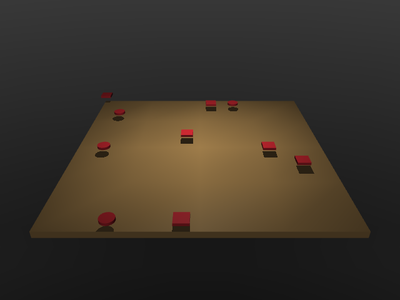

In [16]:
# @title Debris (Geoms)
def debris_with_simple_geoms(spec=None, grid_loc=[0, 0], name='plane'):
  SQUARE_LENGTH = 2
  THICKNESS = 0.05
  BROWN = [0.460, 0.362, 0.216, 1.0]
  RED = [0.6, 0.12, 0.15, 1.0]

  if spec == None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX

  # Create tile
  body = spec.worldbody.add_body(pos=grid_loc + [0], name=name)
  body.add_geom(size=[SQUARE_LENGTH, SQUARE_LENGTH, THICKNESS], rgba=BROWN )

  # Simple Geoms
  x_beginning, y_end = [-SQUARE_LENGTH + THICKNESS] * 2
  x_end, y_beginning = [SQUARE_LENGTH - THICKNESS] * 2

  x_grid = np.linspace(x_beginning, x_end, 10)
  y_grid = np.linspace(y_beginning, y_end, 10)

  for i in range(10):
    x = np.random.choice(x_grid)
    y = np.random.choice(y_grid)

    pos=[grid_loc[0] + x, grid_loc[1] + y, 0.2]

    g_type = None
    size = None
    if random.randint(0, 1):
      g_type = mj.mjtGeom.mjGEOM_BOX
      size = [0.1, 0.1, 0.02]
    else:
      g_type = mj.mjtGeom.mjGEOM_CYLINDER
      size = [0.1, 0.02, 0]

    body = spec.worldbody.add_body(pos=pos, name=f'g{i}_{name}', mass=1)
    body.add_geom(type=g_type, size=size, rgba=RED)
    body.add_freejoint()

render_tile(debris_with_simple_geoms)

""

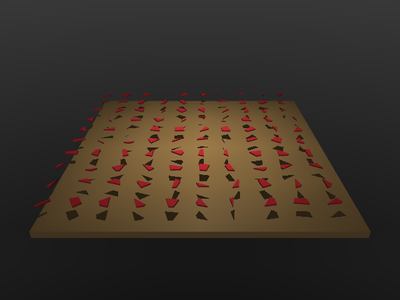

In [17]:
# @title Debris (Mesh)
def debris(spec=None, grid_loc=[0, 0] , name='debris'):
  SQUARE_LENGTH = 2
  THICKNESS = 0.05
  STEP = THICKNESS * 8
  SCALE = 0.1
  BROWN = [0.460, 0.362, 0.216, 1.0]
  RED = [0.6, 0.12, 0.15, 1.0]

  if spec == None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX
  main.mesh.scale = np.array([SCALE]*3, dtype=np.float64)

  x_beginning = -SQUARE_LENGTH + THICKNESS
  y_beginning = SQUARE_LENGTH - THICKNESS

  # Create tile
  body = spec.worldbody.add_body(pos=grid_loc + [0], name=name)
  body.add_geom(size=[SQUARE_LENGTH, SQUARE_LENGTH, THICKNESS], rgba=BROWN)

  # Place debris on the tile
  for i in range(10):
    for j in range(10):
      # draw on xy plane
      drawing = np.random.normal(size=(4, 2))
      drawing /= np.linalg.norm(drawing, axis=1, keepdims=True)
      z = np.zeros((drawing.shape[0], 1))
      # Add z value to drawing
      base = np.concatenate((drawing, z), axis=1)
      # Extrude drawing
      z_extrusion = np.full((drawing.shape[0], 1), THICKNESS * 4)
      top = np.concatenate((drawing, z_extrusion), axis=1)
      # Combine to get a mesh
      mesh = np.vstack((base, top))

      # Create body and add the mesh to the geom of the body
      spec.add_mesh(name=f'd{i}_{j}_{name}', uservert=mesh.flatten())
      pos=[grid_loc[0] + x_beginning + i * STEP,
           grid_loc[1] + y_beginning - j * STEP,
           0.2]

      body = spec.worldbody.add_body(pos=pos, name=f'd{i}_{j}_{name}', mass=1)
      body.add_geom(type=mj.mjtGeom.mjGEOM_MESH, meshname=f'd{i}_{j}_{name}',
                    rgba=RED)
      body.add_freejoint()

render_tile(debris)

""

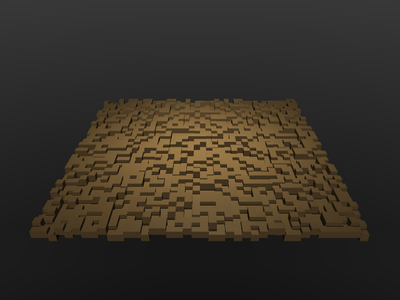

In [18]:
# @title Boxy Terrain
def boxy_terrain(spec=None, grid_loc=[0, 0], name='boxy_terrain'):
  SQUARE_LENGTH = 2
  CUBE_LENGTH = 0.05
  GRID_SIZE = int(SQUARE_LENGTH / CUBE_LENGTH)
  STEP = CUBE_LENGTH * 2
  BROWN = [0.460, 0.362, 0.216, 1.0]

  if spec == None:
    spec=mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX

  # Create tile
  body = spec.worldbody.add_body(pos=grid_loc + [0], name=name)

  x_beginning = -SQUARE_LENGTH + CUBE_LENGTH
  y_beginning = SQUARE_LENGTH - CUBE_LENGTH
  for i in range(GRID_SIZE):
    for j in range(GRID_SIZE):
      body.add_geom(
        pos=[x_beginning + i * STEP ,
             y_beginning - j * STEP ,
             random.randint(-1, 1) * CUBE_LENGTH
        ],
        size=[CUBE_LENGTH] * 3,
        rgba=BROWN
      )

render_tile(boxy_terrain)

""

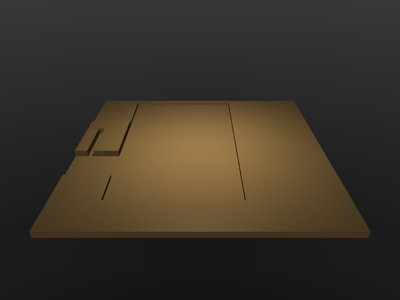

In [19]:
# @title Box (Extrusion | Cut)
def box_extrusions(spec=None, grid_loc=[0, 0], complex=False,
                   name='box_extrusions'):
  # Warning! complex sometimes leads to creation of holes
  SQUARE_LENGTH = 2
  CUBE_LENGTH = 0.05
  GRID_SIZE = int(SQUARE_LENGTH / CUBE_LENGTH)
  STEP = CUBE_LENGTH * 2
  BROWN = [0.460, 0.362, 0.216, 1.0]

  if spec == None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX

  # Create tile
  body = spec.worldbody.add_body(pos=grid_loc + [0], name=name)

  x_beginning = -SQUARE_LENGTH + CUBE_LENGTH
  y_beginning = SQUARE_LENGTH - CUBE_LENGTH

  # Create initial grid and store geoms ref
  grid = [[ 0 for _ in range(GRID_SIZE)] for _ in range(GRID_SIZE)]
  for i in range(GRID_SIZE):
    for j in range(GRID_SIZE):
      ref = body.add_geom(
        pos=[x_beginning + i * STEP, y_beginning - j * STEP, 0],
        size=[CUBE_LENGTH] * 3,
        rgba = BROWN
      )
      grid[i][j] = ref

  # Extrude or Cut operation using the boxes
  for _ in range(random.randint(4, 50)):
    box = None
    while box == None:
      # Create a box
      start = (random.randint(0, GRID_SIZE - 2), random.randint(0, GRID_SIZE - 2))
      dim = (random.randint(0, GRID_SIZE - 2), random.randint(0, GRID_SIZE-2))
      # Make suer box is valid
      if start[0] + dim [0] < len(grid) and start[1] + dim [1] < len(grid):
        box = {"start":start, "dim":dim}

    # Use the box to Cut or Extrude
    operation = random.choice([1, -1])
    start = box["start"]
    dim = box["dim"]
    for i in range(start[0], dim[0]):
      for j in range(start[1], dim[1]):
        tile = grid[i][j]
        if complex:
          tile.pos[2] += operation * CUBE_LENGTH
        else:
          tile.pos[2] = operation * CUBE_LENGTH

render_tile(box_extrusions)

""

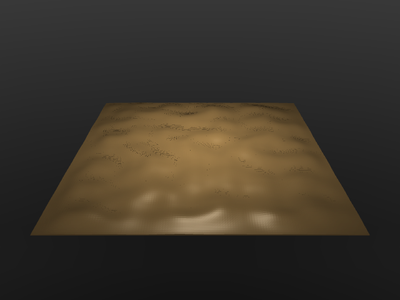

In [20]:
# @title Heightfield
def h_field(spec=None, grid_loc=[0, 0], name='h_field'):
  SQUARE_LENGTH = 2
  HEIGHT = 0.1
  BROWN_RGBA = [0.460, 0.362, 0.216, 1.0]

  if spec is None:
    spec = mj.MjSpec()

  size = 128
  noise = perlin((size, size), (8, 8))

  # Remap noise to 0 to 1
  noise = (noise + 1)/2
  noise -= np.min(noise)
  noise /= np.max(noise)

  # Makes the edges slope down to avoid sharp boundary
  noise *= edge_slope(size)

  # Create height field
  hfield = spec.add_hfield(name=name,
                           size=[SQUARE_LENGTH, SQUARE_LENGTH,
                                 HEIGHT, HEIGHT/10],
                           nrow=noise.shape[0],
                           ncol=noise.shape[1],
                           userdata=noise.flatten())

  body = spec.worldbody.add_body(pos=grid_loc + [0], name=name)
  body.add_geom(type=mj.mjtGeom.mjGEOM_HFIELD, hfieldname=name,
                rgba=BROWN_RGBA)

render_tile(h_field)

""

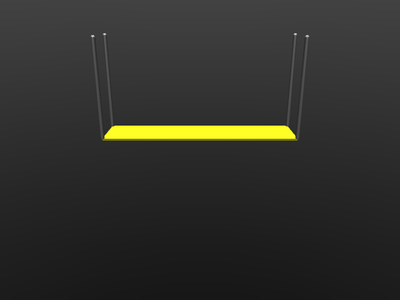

In [21]:
# @title Floating platform
def floating_platform(spec=None, gird_loc=[0, 0, 0], name='platform'):
  PLATFORM_LENGTH = 0.5
  WIDTH = 0.12
  INWARD_OFFSET = 0.008
  THICKNESS = 0.005
  SIZE = [PLATFORM_LENGTH, WIDTH, THICKNESS]
  TENDON_LENGTH = 0.5
  Z_OFFSET = 0.1

  GOLD = [0.850, 0.838, 0.119, 1]

  if spec == None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX

  # Platform with sites
  gird_loc[2] += Z_OFFSET
  platform = spec.worldbody.add_body(pos=gird_loc, name=name)
  platform.add_geom(size=SIZE, rgba=GOLD)
  platform.add_freejoint()

  for x_dir in [-1, 1]:
    for y_dir in [-1, 1]:
      # Add site to world
      vector = np.array([x_dir *  PLATFORM_LENGTH,
                         y_dir * (WIDTH - INWARD_OFFSET)])
      x_w = gird_loc[0] + vector[0]
      y_w = gird_loc[1] + vector[1]
      z_w = gird_loc[2] + TENDON_LENGTH
      # Rotate sites by theta
      spec.worldbody.add_site(name=f'{name}_hook_{x_dir}_{y_dir}',
                              pos=[ x_w, y_w, z_w],
                              size=[0.01, 0, 0])
      # Add site to platform
      x_p = x_dir *  PLATFORM_LENGTH
      y_p = y_dir * (WIDTH - INWARD_OFFSET)
      platform.add_site(name=f'{name}_anchor_{x_dir}_{y_dir}',
                        pos=[ x_p, y_p, THICKNESS * 2],
                        size=[0.01, 0, 0])

      # Connect tendon to sites
      thread = spec.add_tendon(name=f'{name}_thread_{x_dir}_{y_dir}',
                               limited=True,
                               range=[0, TENDON_LENGTH], width=0.01 )
      thread.wrap_site(f'{name}_hook_{x_dir}_{y_dir}')
      thread.wrap_site(f'{name}_anchor_{x_dir}_{y_dir}')

render_tile(floating_platform, cam_distance=2, cam_elevation=-20)

""

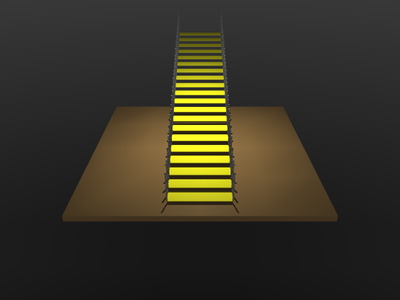

In [22]:
# @title Simple stairs
def simple_suspended_stair(spec=None, grid_loc=[0, 0], num_stair=20,
                           name="simple_suspended_stair"):
  BROWN= [0.460, 0.362, 0.216, 1.0]
  SQUARE_LENGTH = 2
  THICKNESS = 0.05
  OFFSET_Y = -4/5 * SQUARE_LENGTH

  V_STEP = 0.076
  H_STEP = 0.12

  if spec == None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX

  # Create tile
  body = spec.worldbody.add_body(pos=grid_loc + [0], name=name)
  body.add_geom(size=[SQUARE_LENGTH, SQUARE_LENGTH, THICKNESS], rgba=BROWN)

  # Create Stairs
  for i in range(num_stair):
    floating_platform(spec,[grid_loc[0],
                            OFFSET_Y + grid_loc[1] + i * 2 * H_STEP,
                            i * V_STEP],
                       name =f'{name}_p_{i}')

render_tile(simple_suspended_stair,cam_distance=7, cam_elevation=-30)

""

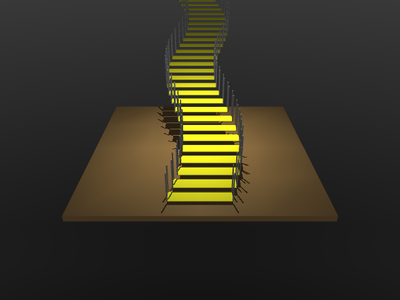

In [23]:
# @title Sinusoidal stairs
def sin_suspended_stair(spec, grid_loc=[0, 0], num_stair=40,
                        name="sin_suspended_stair"):
  BROWN = [0.460, 0.362, 0.216, 1.0]
  SQUARE_LENGTH = 2
  THICKNESS = 0.05
  OFFSET_Y = -4/5 * SQUARE_LENGTH

  V_STEP = 0.076
  H_STEP = 0.12
  AMPLITUDE = 0.2
  FREQUENCY = 0.5

  if spec == None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX

  # Plane
  body = spec.worldbody.add_body(pos=grid_loc + [0], name=name)
  body.add_geom(size=[SQUARE_LENGTH, SQUARE_LENGTH, THICKNESS], rgba=BROWN)

  for i in range(num_stair):
    x_step = AMPLITUDE * np.sin(2 * np.pi * FREQUENCY * (i * H_STEP))
    floating_platform(spec, [grid_loc[0] + x_step,
                            OFFSET_Y + grid_loc[1] + i * 2 * H_STEP,
                            i * V_STEP],
                           name=f'{name}_p_{i}')

render_tile(sin_suspended_stair,cam_distance=7, cam_elevation=-30)

""

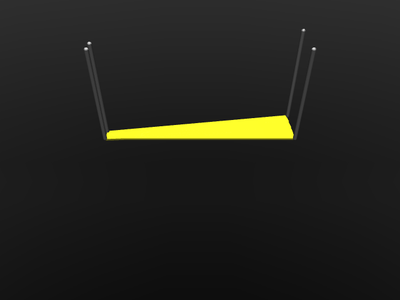

In [24]:
# @title Floating platform for circular stair
def floating_platform_for_circular_stair(spec=None, gird_loc=[0, 0, 0] ,theta=0,
                                         name='platform'):
  PLATFORM_LENGTH = 0.5
  TENDON_LENGTH = 0.5
  WIDTH = 0.12/4 # Platform (body) is made of 4 separate geoms
  THICKNESS = 0.005
  SIZE = [PLATFORM_LENGTH, WIDTH, THICKNESS]
  Z_OFFSET = 0.1

  GOLD = [0.850, 0.838, 0.119, 1]

  if spec == None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX
  spec.compiler.degree = False

  # Platform with sites
  gird_loc[2] += Z_OFFSET
  platform = spec.worldbody.add_body(pos=gird_loc, name=name, euler=[0, 0, theta])
  platform.add_geom(pos=[0, 0, 0] , size=SIZE, euler=[0, 0, 0],rgba=GOLD)
  platform.add_geom(pos=[0, 0.02, 0], size=SIZE, euler=[0, 0, 0.05],rgba=GOLD)
  platform.add_geom(pos=[0, 0.05, 0], size=SIZE, euler=[0, 0, 0.1],rgba=GOLD)
  platform.add_geom(pos=[0, 0.08, 0], size=SIZE, euler=[0, 0, 0.15],rgba=GOLD)
  platform.add_freejoint()

  for i, x_dir in enumerate([-1, 1]):
    for j, y_dir in enumerate([-1, 1]):
      # Rotate sites by theta
      rotation_matrix = np.array([[np.cos(-theta), -np.sin(-theta)],
                                  [np.sin(-theta), np.cos(-theta)]])
      vector = np.array([x_dir * PLATFORM_LENGTH, y_dir * WIDTH ])
      if i + j == 2:
        vector = np.array([x_dir * PLATFORM_LENGTH, y_dir * 6 * WIDTH ])
      vector = np.dot(vector , rotation_matrix)
      x_w = gird_loc[0] + vector[0]
      y_w = gird_loc[1] + vector[1]
      z_w = gird_loc[2] + TENDON_LENGTH

      # Add site to world
      spec.worldbody.add_site(name=f'{name}_hook_{x_dir}_{y_dir}',
                              pos=[ x_w, y_w, z_w],
                              size=[0.01, 0, 0])
      # Add site to platform
      x_p = x_dir *  PLATFORM_LENGTH
      y_p = y_dir * WIDTH
      if i + j == 2:
        y_p = y_dir * 6 * WIDTH
      platform.add_site(name=f'{name}_anchor_{x_dir}_{y_dir}',
                        pos=[x_p, y_p, THICKNESS * 2],
                        size=[0.01, 0, 0])

      # Connect tendon to sites
      thread = spec.add_tendon(name=f'{name}_thread_{x_dir}_{y_dir}', limited=True,
                               range=[0, TENDON_LENGTH], width=0.01 )
      thread.wrap_site(f'{name}_hook_{x_dir}_{y_dir}')
      thread.wrap_site(f'{name}_anchor_{x_dir}_{y_dir}')

render_tile(floating_platform_for_circular_stair,cam_distance=2, cam_elevation=-40)

""

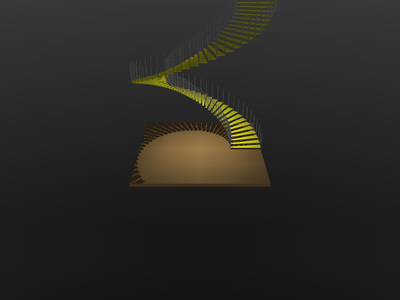

In [25]:
# @title Circular stairs
def circular_stairs(spec, grid_loc=[0, 0], num_stair=60, name="circular_stairs"):
  BROWN_RGBA = [0.460, 0.362, 0.216, 1.0]
  SQUARE_LENGTH = 2
  THICKNESS = 0.05

  RADIUS = 1.5
  V_STEP = 0.076

  if spec == None:
    spec = mj.MjSpec()

  # Defaults
  main = spec.default
  main.geom.type = mj.mjtGeom.mjGEOM_BOX
  spec.compiler.degree = False

  # Plane
  body = spec.worldbody.add_body(pos=grid_loc + [0], name=name)
  body.add_geom(size = [SQUARE_LENGTH, SQUARE_LENGTH, THICKNESS], rgba = BROWN_RGBA )

  theta_step = 2 * np.pi / num_stair
  for i in range(num_stair):
    theta = i * theta_step
    x = grid_loc[0] + RADIUS * np.cos(theta)
    y = grid_loc[1] + RADIUS * np.sin(theta)
    z = i * V_STEP

    floating_platform_for_circular_stair(spec, [x, y, z], theta=theta, name=f'{name}_p_{i}')

render_tile(circular_stairs,cam_distance=12, cam_elevation=-30)

In [26]:
# @title Tile Generator
def add_tile(spec=None, grid_loc=[0, 0]):
  if spec is None:
    spec = mj.MjSpec()

  tile_type = random.randint(0, 9)

  if tile_type == 0:
    debris_with_simple_geoms(spec, grid_loc, name=f"plane_{grid_loc[0]}_{grid_loc[1]}")
  elif tile_type == 1:
    stairs(spec, grid_loc, name=f"stairs_up_{grid_loc[0]}_{grid_loc[1]}",direction=1)
  elif tile_type == 2:
    stairs(spec, grid_loc, name=f"stairs_down_{grid_loc[0]}_{grid_loc[1]}",direction=-1)
  elif tile_type == 3:
    debris(spec, grid_loc, name=f"debris_{grid_loc[0]}_{grid_loc[1]}")
  elif tile_type == 4:
    box_extrusions(spec, grid_loc, name=f"box_extrusions_{grid_loc[0]}_{grid_loc[1]}")
  elif tile_type == 5:
    boxy_terrain(spec, grid_loc, name=f"boxy_terrain_{grid_loc[0]}_{grid_loc[1]}")
  elif tile_type == 6:
    h_field(spec, grid_loc, name=f"h_field_{grid_loc[0]}_{grid_loc[1]}")
  elif tile_type == 7:
    simple_suspended_stair(spec, grid_loc, name=f"sss_{grid_loc[0]}_{grid_loc[1]}")
  elif tile_type == 8:
    sin_suspended_stair(spec, grid_loc, name=f"sinss_{grid_loc[0]}_{grid_loc[1]}")
  elif tile_type == 9:
    circular_stairs(spec, grid_loc, name=f"circular_s_{grid_loc[0]}_{grid_loc[1]}")
  return spec

""

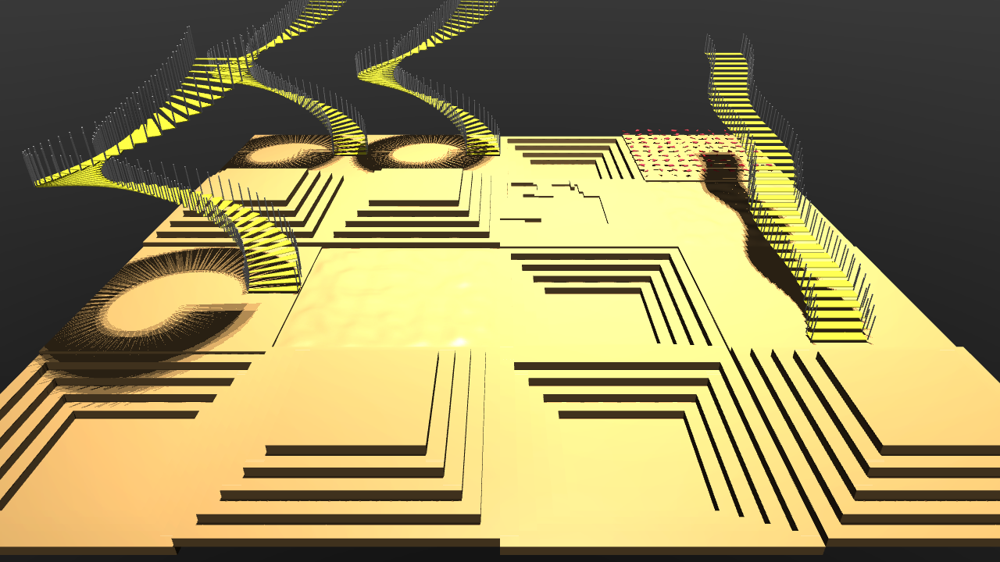

In [27]:
# @title Generate Terrain
arena_xml = """
<mujoco>
  <visual>
    <headlight diffuse=".5 .5 .5" specular="1 1 1"/>
    <global elevation="-10" offwidth="2048" offheight="1536"/>
    <quality shadowsize="8192"/>
  </visual>

  <asset>
    <texture type="skybox" builtin="gradient" rgb1=".5 .5 .5" rgb2="0 0 0" width="10" height="10"/>
    <texture type="2d" name="groundplane" builtin="checker" mark="edge" rgb1="1 1 1" rgb2="1 1 1" markrgb="0 0 0" width="300" height="300"/>
    <material name="groundplane" texture="groundplane" texuniform="true" texrepeat="5 5" reflectance="0.3"/>
  </asset>

  <worldbody>
  </worldbody>
</mujoco>
"""

spec = mj.MjSpec.from_string(arena_xml)

spec.option.enableflags |= mj.mjtEnableBit.mjENBL_OVERRIDE
spec.option.timestep = 0.0001
spec.compiler.degree = False

main = spec.default
main.geom.solref = [0.001, 1]

# Add lights
for x in [-1, 1]:
  for y in [-1, 1]:
    spec.worldbody.add_light(pos=[x, y, 40], dir=[-x, -y, -15])

SQUARE_LENGTH = 2
for i in range(-2, 2):
  for j in range(-2, 2):
    add_tile(spec=spec, grid_loc=[i * 2 * SQUARE_LENGTH, j * 2 * SQUARE_LENGTH])

model = spec.compile()
data = mj.MjData(model)

cam = mj.MjvCamera()
mj.mjv_defaultCamera(cam)
cam.lookat = [-2, 0, -2]
cam.distance = 18
cam.elevation = -30

with mj.Renderer(model, 720, 1280) as renderer:
  mj.mj_forward(model, data)
  renderer.update_scene(data,cam)
  media.show_image(renderer.render())

# Model editing

In [28]:
# @title Get resources

# Get Models
print('Getting MuJoCo humanoid XML description from GitHub:')
!git clone https://github.com/google-deepmind/mujoco
humanoid_file = 'mujoco/model/humanoid/humanoid.xml'
humanoid100_file = 'mujoco/model/humanoid/humanoid100.xml'
print('Getting MuJoCo Fly and Franka XML description from GitHub:')
!git clone https://github.com/google-deepmind/mujoco_menagerie
fly_file = 'mujoco_menagerie/flybody/fruitfly.xml'
franka_file = 'mujoco_menagerie/franka_fr3/fr3.xml'

# Camera options
cam = mj.MjvCamera()
mj.mjv_defaultCamera(cam)
cam.elevation = -10
cam.lookat = [0, 0, 1]
cam.distance = 4
cam.azimuth = 135

# Arena
arena_xml = """
<mujoco>
  <visual>
    <headlight diffuse=".5 .5 .5" specular="1 1 1"/>
    <global offwidth="2048" offheight="1536"/>
    <quality shadowsize="8192"/>
  </visual>

  <asset>
    <texture type="skybox" builtin="gradient" rgb1="1 1 1" rgb2="1 1 1" width="10" height="10"/>
    <texture type="2d" name="groundplane" builtin="checker" mark="edge" rgb1="1 1 1" rgb2="1 1 1" markrgb="0 0 0" width="400" height="400"/>
    <material name="groundplane" texture="groundplane" texrepeat="45 45" reflectance="0"/>
  </asset>

  <worldbody>
    <geom name="floor" size="10 10 0.1" type="plane" material="groundplane"/>
  </worldbody>
</mujoco>
"""


Getting MuJoCo humanoid XML description from GitHub:
Cloning into 'mujoco'...
remote: Enumerating objects: 67495, done.
remote: Counting objects: 100% (2385/2385), done.
remote: Compressing objects: 100% (929/929), done.
remote: Total 67495 (delta 2052), reused 1459 (delta 1456), pack-reused 65110 (from 4)
Receiving objects: 100% (67495/67495), 146.86 MiB | 19.36 MiB/s, done.
Resolving deltas: 100% (51550/51550), done.
Getting MuJoCo Fly and Franka XML description from GitHub:
Cloning into 'mujoco_menagerie'...
remote: Enumerating objects: 8487, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 8487 (delta 3), reused 5 (delta 2), pack-reused 8475 (from 1)
Receiving objects: 100% (8487/8487), 606.50 MiB | 18.10 MiB/s, done.
Resolving deltas: 100% (2500/2500), done.
Updating files: 100% (3211/3211), done.


`mjSpec` elements can be traversed in two ways:
- For elements inside the kinematic tree, the tree can be traversed using the `first` and `next` functions.
- For all other elements, we provide a list.



In [29]:
#@title Traversing the spec {vertical-output: true}

spec = mj.MjSpec.from_file(humanoid_file)

# Function that recursively prints all body names
def print_bodies(parent, level=0):
  body = parent.first_body()
  while body:
    print(''.join(['-' for i in range(level)]) + body.name)
    print_bodies(body, level + 1)
    body = parent.next_body(body)

print("The spec has the following actuators:")
for actuator in spec.actuators:
  print(actuator.name)

print("\nThe spec has the following bodies:")
print_bodies(spec.worldbody)

The spec has the following actuators:
abdomen_z
abdomen_y
abdomen_x
hip_x_right
hip_z_right
hip_y_right
knee_right
ankle_y_right
ankle_x_right
hip_x_left
hip_z_left
hip_y_left
knee_left
ankle_y_left
ankle_x_left
shoulder1_right
shoulder2_right
elbow_right
shoulder1_left
shoulder2_left
elbow_left

The spec has the following bodies:
torso
-head
-waist_lower
--pelvis
---thigh_right
----shin_right
-----foot_right
---thigh_left
----shin_left
-----foot_left
-upper_arm_right
--lower_arm_right
---hand_right
-upper_arm_left
--lower_arm_left
---hand_left


An `mjSpec` can be compiled multiple times. If the state has to be preserved between different compilations, then the function `recompile()` must be used, which returns a new `mjData` that contains the mapped state, possibly having a different dimension from the origin.

/tmp/ipykernel_768/1276069564.py:4: UserWarning: Attach conflict when attaching 'Humanoid' to 'Humanoid and 100 objects', policy is 'warning'
zfar: parent has 50 (default), child has 30, keeping parent value
  model = spec.compile()


""

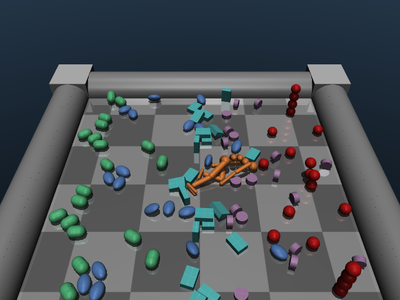

""

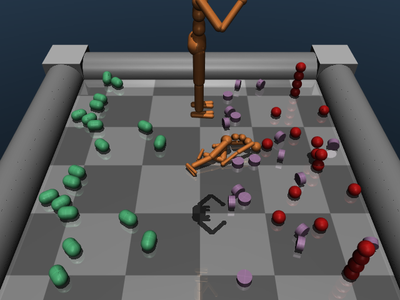

In [30]:
#@title Model re-compilation with state preservation {vertical-output: true}

spec = mj.MjSpec.from_file(humanoid100_file)
model = spec.compile()
data = mj.MjData(model)

# Run for 5 seconds
for i in range(1000):
  mj.mj_step(model, data)

# Show result
render(model, data)

# Create list of all bodies we want to delete
body = spec.worldbody.first_body()
delete_list = []
while body:
  geom_type = body.first_geom().type
  if (geom_type == mj.mjtGeom.mjGEOM_BOX or
      geom_type == mj.mjtGeom.mjGEOM_ELLIPSOID):
    delete_list.append(body)
  body = spec.worldbody.next_body(body)

# Remove all bodies in the list from the spec
for body in delete_list:
  spec.delete(body)

# # Add another humanoid
spec_humanoid = mj.MjSpec.from_file(humanoid_file)
attachment_frame = spec.worldbody.add_frame(pos=[0, -1, 2])
attachment_frame.attach_body(spec_humanoid.body('torso'), 'a', 'b')

# Recompile preserving the state
new_model, new_data = spec.recompile(model, data)

# Show result
render(new_model, new_data)

Let us load the humanoid model and inspect it.

""

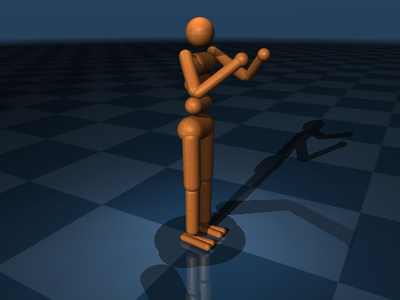

In [31]:
#@title Humanoid model {vertical-output: true}

spec = mj.MjSpec.from_file(humanoid_file)

model = spec.compile()
render(model)

We wish to remove the arms and replace them with the legs. This can be done by first storing the arm positions into frames attached to the torso. Then we can detach the arms and self-attach the legs into the frames.

""

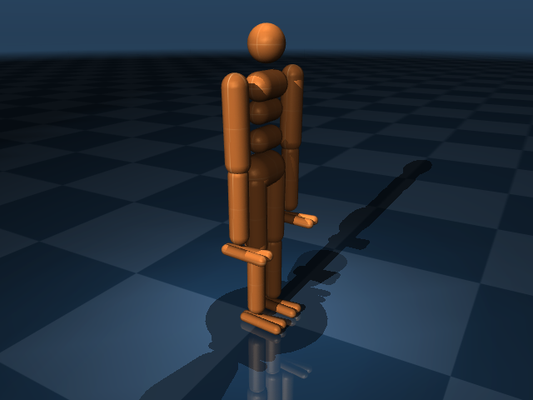

In [32]:
#@title Humanoid with arms replaced by legs {vertical-output: true}

spec = mj.MjSpec.from_file(humanoid_file)
spec.copy_during_attach = True

# Get the torso, arm, and leg bodies
arm_left = spec.body('upper_arm_left')
arm_right = spec.body('upper_arm_right')
leg_left = spec.body('thigh_left')
leg_right = spec.body('thigh_right')
torso = spec.body('torso')

# Attach frames at the arm positions
shoulder_left = torso.add_frame(pos=arm_left.pos)
shoulder_right = torso.add_frame(pos=arm_right.pos)

# Remove the arms
spec.delete(arm_left)
spec.delete(arm_right)

# Add new legs
shoulder_left.attach_body(leg_left, 'shoulder', 'left')
shoulder_right.attach_body(leg_right, 'shoulder', 'right')

model = spec.compile()
render(model, height=400)

Similarly, different models can be attach together. Here, the right arm is detached and a robot arm from a different model is attached in its place.

/tmp/ipykernel_768/2126011594.py:21: UserWarning: Attach conflict when attaching 'fr3' to 'Humanoid', policy is 'warning'
integrator: parent has 0 (default), child has 3, keeping parent value
  model = spec.compile()


""

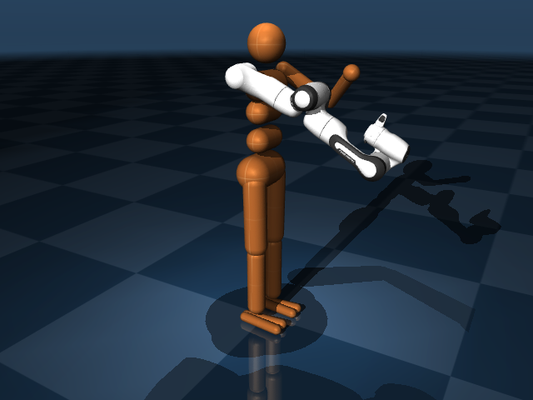

In [33]:
#@title Humanoid with Franka arm {vertical-output: true}

spec = mj.MjSpec.from_file(humanoid_file)
franka = mj.MjSpec.from_file(franka_file)

if hasattr(spec, 'compiler'):
  spec.compiler.degree = False  # MuJoCo dev (next release).
else:
  spec.degree = False  # MuJoCo release

# Replace right arm with frame
arm_right = spec.body('upper_arm_right')
torso = spec.body('torso')
shoulder_right = torso.add_frame(pos=arm_right.pos, quat=[0, 0.8509035, 0, 0.525322])
spec.delete(arm_right)

# Attach Franka arm to humanoid
franka_arm = franka.body('fr3_link2')
shoulder_right.attach_body(franka_arm, 'franka', '')

model = spec.compile()
render(model, height=400)

When doing this, the actuators and all other objects referenced by the attached sub-tree are imported in the new model. All assets are currently imported, referenced or not.

In [34]:
#@title Imported actuators {vertical-output: true}

for actuator in spec.actuators:
  print(actuator.name)

abdomen_z
abdomen_y
abdomen_x
hip_x_right
hip_z_right
hip_y_right
knee_right
ankle_y_right
ankle_x_right
hip_x_left
hip_z_left
hip_y_left
knee_left
ankle_y_left
ankle_x_left
shoulder1_left
shoulder2_left
elbow_left
frankafr3_joint2
frankafr3_joint3
frankafr3_joint4
frankafr3_joint5
frankafr3_joint6
frankafr3_joint7


Domain randomization can be performed by attaching multiple times the same spec, edited each time with a new instance of randomized parameters.

/tmp/ipykernel_768/3715605718.py:33: UserWarning: Attach conflict when attaching 'Humanoid', policy is 'warning'
timestep: parent has 0.002 (default), child has 0.005, keeping parent value
zfar: parent has 50 (default), child has 30, keeping parent value
  model = spec.compile()


""

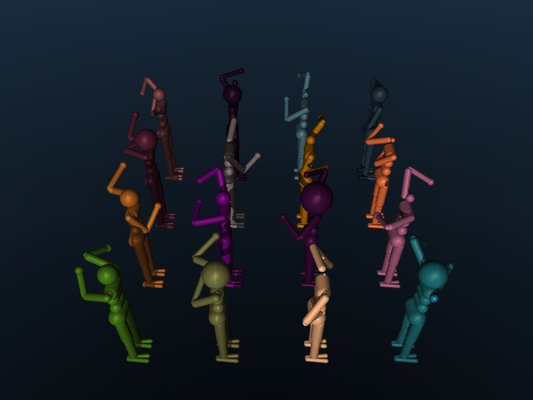

In [35]:
#@title Humanoid with randomized heads and arm poses {vertical-output: true}

humanoid = mj.MjSpec.from_file(humanoid_file)
spec = mj.MjSpec()
spec.copy_during_attach = True

# Delete all key frames to avoid name conflicts
while humanoid.keys:
  humanoid.delete(humanoid.keys[-1])

# Create a grid of humanoids by attaching humanoid to spec multiple times
for i in range(4):
  for j in range(4):
    humanoid.materials[0].rgba = [
        np.random.uniform(), np.random.uniform(),
        np.random.uniform(), 1]  # Randomize color
    humanoid.body('head').first_geom().size = [
        .18*np.random.uniform(), 0, 0]  # Randomize head size
    humanoid.body('upper_arm_left').quat = [
        np.random.uniform(), np.random.uniform(),
        np.random.uniform(), np.random.uniform()]  # Randomize left arm orientation
    humanoid.body('upper_arm_right').quat = [
        np.random.uniform(), np.random.uniform(),
        np.random.uniform(), np.random.uniform()]  # Randomize right arm orientation

    # attach randomized humanoid to parent spec
    frame = spec.worldbody.add_frame(pos=[i, j, 0])
    frame.attach_body(humanoid.body('torso'), str(i), str(j))

spec.worldbody.add_light(mode=mj.mjtCamLight.mjCAMLIGHT_TARGETBODYCOM,
                         targetbody='3torso3', diffuse=[.8, .8, .8],
                         specular=[0.3, 0.3, 0.3], pos=[0, -6, 4], cutoff=30)
model = spec.compile()
render(model, height=400)

## Model scaling

/tmp/ipykernel_768/1186076585.py:44: UserWarning: Attach conflict when attaching 'Humanoid', policy is 'warning'
timestep: parent has 0.002 (default), child has 0.005, keeping parent value
zfar: parent has 50 (default), child has 30, keeping parent value
  model = spec.compile()


""

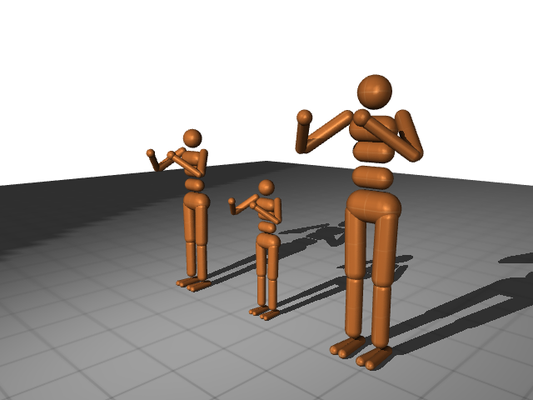

In [36]:
#@title Uniformly scale humanoid {vertical-output: true}

def scale_spec(spec, scale):
  scaled_spec = spec.copy()
  # Traverse the kinematic tree, scaling all geoms
  def scale_bodies(parent, scale=1.0):
    body = parent.first_body()
    while body:
      if body.pos is not None:
        body.pos = body.pos * scale
      for geom in body.geoms:
        geom.fromto = geom.fromto * scale
        geom.size = geom.size * scale
        if geom.pos is not None:
          geom.pos = geom.pos * scale
      scale_bodies(body, scale)
      body = parent.next_body(body)

  scale_bodies(scaled_spec.body('world'), scale)
  return scaled_spec

spec = mj.MjSpec.from_string(arena_xml)
humanoid = mj.MjSpec.from_file(humanoid_file)
small_humanoid = scale_spec(humanoid, 0.75)
large_humanoid = scale_spec(humanoid, 1.25)

# Create a line-up of humanoids
frame = spec.worldbody.add_frame(pos=[-1, 0, 0],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2])
frame.attach_body(humanoid.body('torso'), str(0))

frame = spec.worldbody.add_frame(pos=[0, 0, 0],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2])
frame.attach_body(small_humanoid.body('torso'), str(1))

frame = spec.worldbody.add_frame(pos=[1, 0, 0],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2]  )
frame.attach_body(large_humanoid.body('torso'), str(2))


spec.worldbody.add_light(mode=mj.mjtCamLight.mjCAMLIGHT_TARGETBODYCOM,
                         targetbody='1torso', diffuse=[.8, .8, .8],
                         specular=[0.3, 0.3, 0.3], pos=[0, -6, 4], cutoff=30)
model = spec.compile()
render(model, height=400, camera=cam)

We can scale the size of a model by traversing the kinematic tree and applying the scale to the relevant geoms. Above we can see humanoids of three different sizes.

In [37]:
# @title Scaling actuator forces {vertical-output: true}

def scale_spec(spec, scale, scale_actuators=False):
  scaled_spec = spec.copy()
  # Traverse the kinematic tree, scaling all geoms
  def scale_bodies(parent, scale=1.0):
    body = parent.first_body()
    while body:
      if body.pos is not None:
        body.pos = body.pos * scale
      for geom in body.geoms:
        geom.fromto = geom.fromto * scale
        geom.size = geom.size * scale
        if geom.pos is not None:
          geom.pos = geom.pos * scale
      scale_bodies(body, scale)
      body = parent.next_body(body)

  if scale_actuators:
    # scale gear
    for actuator in scaled_spec.actuators:
      # scale the actuator gear by (scale ** 2),
      # this is because muscle force-generating capacity
      # scales with the cross-sectional area of the muscle
      actuator.gear = actuator.gear * scale * scale

  # scale the z-position of the humanoid for all keypoints
  for keypoint in scaled_spec.keys:
    qpos = keypoint.qpos
    qpos[2] = qpos[2] * scale
    keypoint.qpos = qpos
    keypoint.qpos[2] = keypoint.qpos[2] * scale

  scale_bodies(scaled_spec.body('world'), scale)
  return scaled_spec

# Create specs
scale = 0.6
spec = mj.MjSpec.from_string(arena_xml)
humanoid = mj.MjSpec.from_file(humanoid_file)
small_humanoid = scale_spec(humanoid, scale)
small_humanoid_actuators_scaled = scale_spec(humanoid, scale, True)

# Create a line-up of humanoids
squat_qpos = []

# Add unscaled humanoid
frame = spec.worldbody.add_frame(pos=[-1, 0, 0],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2])
frame.attach_body(humanoid.body('torso'), str(0))
# Record squat pose
humanoid_squat = np.array(humanoid.key('squat').qpos)
humanoid_squat[:2] = frame.pos[:2]
humanoid_squat[3:7] = frame.quat
squat_qpos.append(humanoid_squat)

# Add small humanoid
frame = spec.worldbody.add_frame(pos=[0, 0, 0],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2])
frame.attach_body(small_humanoid.body('torso'), str(1))
# Record squat pose
humanoid_squat = np.array(small_humanoid.key('squat').qpos)
humanoid_squat[:2] = frame.pos[:2]
humanoid_squat[3:7] = frame.quat
squat_qpos.append(humanoid_squat)

# Add small humanoid with scaled actuators
frame = spec.worldbody.add_frame(pos=[1, 0, 0],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2]  )
frame.attach_body(small_humanoid_actuators_scaled.body('torso'), str(2))
# Record squat pose
humanoid_squat = np.array(small_humanoid_actuators_scaled.key('squat').qpos)
humanoid_squat[:2] = frame.pos[:2]
humanoid_squat[3:7] = frame.quat
squat_qpos.append(humanoid_squat)
squat_qpos = np.concatenate(squat_qpos)

spec.worldbody.add_light(mode=mj.mjtCamLight.mjCAMLIGHT_TARGETBODYCOM,
                         targetbody='1torso', diffuse=[.8, .8, .8],
                         specular=[0.3, 0.3, 0.3], pos=[0, -6, 4], cutoff=30)
model = spec.compile()

# Initialize to squat position
data = mj.MjData(model)
data.qpos = squat_qpos

# jumping motion
u_t = lambda t: 10.0 * t / duration

# Simulate and display video.
duration = 2    # (seconds)
framerate = 30  # (Hz)
frames = []

with mj.Renderer(model, 480, 640) as renderer:
  while data.time < duration:
    data.ctrl = u_t(data.time)
    mj.mj_step(model, data)
    if len(frames) < data.time * framerate:
      renderer.update_scene(data, camera=cam)
      pixels = renderer.render()
      frames.append(pixels)

media.show_video(frames, fps=framerate, height=400)

/tmp/ipykernel_768/1709047211.py:81: UserWarning: Attach conflict when attaching 'Humanoid', policy is 'warning'
timestep: parent has 0.002 (default), child has 0.005, keeping parent value
zfar: parent has 50 (default), child has 30, keeping parent value
  model = spec.compile()


This browser does not support the video tag.


We can also apply scaling to the actuators. In the humanoid case, scaling the geoms without scaling the `gear` parameter for the actuators results in a humanoid that can jump higher proportional to its size.

/tmp/ipykernel_768/437767116.py:49: UserWarning: Attach conflict when attaching 'Humanoid', policy is 'warning'
timestep: parent has 0.002 (default), child has 0.005, keeping parent value
zfar: parent has 50 (default), child has 30, keeping parent value
  model = spec.compile()


""

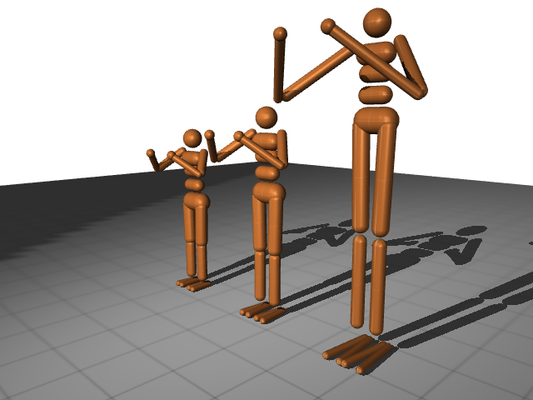

In [38]:
# @title Long-limbed humanoid {vertical-output: true}

def scale_spec(spec, scale):
  scaled_spec = spec.copy()
  # Traverse the kinematic tree, scaling all geoms
  def scale_bodies(parent, scale=1.0):
    if parent is not None:
      for geom in parent.geoms:
        # Only scale fromto, not size to scale length of capsules
        geom.fromto = geom.fromto * scale
        if geom.pos is not None:
          geom.pos = geom.pos * scale
    body = parent.first_body()
    while body:
      if body.pos is not None:
        body.pos = body.pos * scale
      scale_bodies(body, scale)
      body = parent.next_body(body)

  # Scale all the limbs
  scale_bodies(scaled_spec.body('upper_arm_right'), scale)
  scale_bodies(scaled_spec.body('upper_arm_left'), scale)
  scale_bodies(scaled_spec.body('thigh_right'), scale)
  scale_bodies(scaled_spec.body('thigh_left'), scale)
  return scaled_spec

spec = mj.MjSpec.from_string(arena_xml)
humanoid = mj.MjSpec.from_file(humanoid_file)
small_humanoid = scale_spec(humanoid, 1.25)
large_humanoid = scale_spec(humanoid, 2)

# Create a line-up of humanoids by attaching
frame = spec.worldbody.add_frame(pos=[-1, 0, 0],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2])
frame.attach_body(humanoid.body('torso'), str(0), str(0))

frame = spec.worldbody.add_frame(pos=[0, 0, 0.2],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2])
frame.attach_body(small_humanoid.body('torso'), str(0), str(1))

frame = spec.worldbody.add_frame(pos=[1, 0, 0.8],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2]  )
frame.attach_body(large_humanoid.body('torso'), str(0), str(2))


spec.worldbody.add_light(mode=mj.mjtCamLight.mjCAMLIGHT_TARGETBODYCOM,
                         targetbody='0torso1', diffuse=[.8, .8, .8],
                         specular=[0.3, 0.3, 0.3], pos=[0, -6, 4], cutoff=30)
model = spec.compile()

# camera options
render(model, height=400, camera=cam)

We can also apply scaling to the model non-uniformly. In this instance we scale the humanoid to have long limbs, by only applying the scale to the length of the capsule geoms for the arms, legs and feet.

/tmp/ipykernel_768/128585129.py:54: UserWarning: Attach conflict when attaching 'fruitfly', policy is 'warning'
timestep: parent has 0.002 (default), child has 0.0001, keeping parent value
noslip_iterations: parent has 0 (default), child has 3, keeping parent value
density: parent has 0 (default), child has 0.00128, keeping parent value
viscosity: parent has 0 (default), child has 0.000185, keeping parent value
cone: parent has 0 (default), child has 1, keeping parent value
gravity: parent has 0 0 -9.81 (default), child has 0 0 -981, keeping parent value
njmax: parent has -1 (default), child has 300, keeping parent value
nconmax: parent has -1 (default), child has 100, keeping parent value
nkey: parent has 0 (default), child has 1, keeping parent value
  model = spec.compile()


""

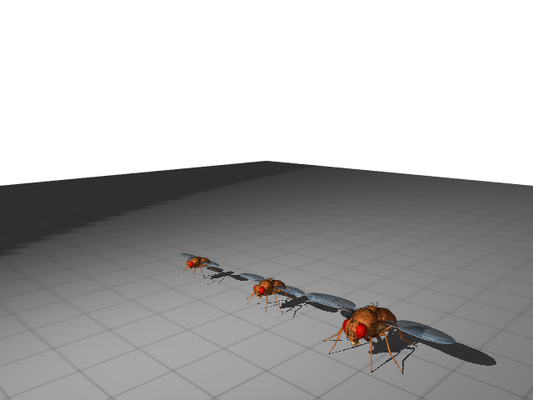

In [39]:
# @title Meshes {vertical-output: true}

def scale_spec(spec, scale):
  scaled_spec = spec.copy()
  # scale all meshes
  for mesh in scaled_spec.meshes:
    if mesh.scale is None:
      mesh.scale = np.ones(3)
    mesh.scale = mesh.scale * scale

  # Traverse the kinematic tree
  def scale_bodies(parent, scale=1.0):
    if parent is not None:
      for geom in parent.geoms:
        if geom.pos is not None:
          geom.pos = geom.pos * scale
    body = parent.first_body()
    while body:
      if body.pos is not None:
        body.pos = body.pos * scale
      scale_bodies(body, scale)
      body = parent.next_body(body)

  # Scale all the limbs
  scale_bodies(scaled_spec.body('world'), scale)

  return scaled_spec

spec = mj.MjSpec.from_string(arena_xml)
fly = mj.MjSpec.from_file(fly_file)
# Remove lights from fly so they are not duplicated in line-up
for light in fly.lights:
  fly.delete(light)

small_fly = scale_spec(fly, 1.25)
large_fly = scale_spec(fly, 2)

# Create a line-up of flys by attaching
frame = spec.worldbody.add_frame(pos=[-1, 0, 0.25],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2])
frame.attach_body(fly.body('thorax'), str(0), str(0))

frame = spec.worldbody.add_frame(pos=[0, 0, 0.25],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2])
frame.attach_body(small_fly.body('thorax'), str(0), str(1))

frame = spec.worldbody.add_frame(pos=[1, 0, 0.25],
                                 quat=[-np.sqrt(2)/2, 0, 0, np.sqrt(2) / 2]  )
frame.attach_body(large_fly.body('thorax'), str(0), str(2))

spec.worldbody.add_light(mode=mj.mjtCamLight.mjCAMLIGHT_TARGETBODYCOM,
                         targetbody='0thorax1', diffuse=[.8, .8, .8],
                         specular=[0.3, 0.3, 0.3], pos=[0, -6, 4], cutoff=30)
model = spec.compile()
render(model, height=400, camera=cam)


# dm_control example

A key feature is the ability to easily attach multiple models into a larger one. Disambiguation of duplicated names from different
models, or multiple instances of the same model is handled via user-defined namespacing.

One example use case is when we want robots with a variable number of joints, as this is a fundamental change to the kinematic structure. The snippets below follow the lines of the [example in dm_control](https://arxiv.org/abs/2006.12983), an older package with similar capabilities.

In [40]:
leg_model = """
<mujoco>
  <compiler angle="radian"/>

  <default>
    <joint damping="2" type="hinge"/>
    <geom type="capsule"/>
  </default>

  <worldbody>
    <body name="thigh">
      <joint name="hip" axis="0 0 1"/>
      <body name="shin">
        <joint name="knee" axis="0 1 0"/>
      </body>
    </body>
  </worldbody>

  <actuator>
    <position joint="hip" kp="10" name="hip"/>
    <position joint="knee" kp="10" name="knee"/>
  </actuator>
</mujoco>
"""

class Leg(object):
  """A 2-DoF leg with position actuators."""
  def __init__(self, length, rgba):
    self.spec = mj.MjSpec.from_string(leg_model)

    # Thigh:
    thigh = self.spec.body('thigh')
    thigh.add_geom(fromto=[0, 0, 0, length, 0, 0], size=[length/4, 0, 0], rgba=rgba)

    # Hip:
    shin = self.spec.body('shin')
    shin.add_geom(fromto=[0, 0, 0, 0, 0, -length], size=[length/5, 0, 0], rgba=rgba)
    shin.pos[0] = length

The `Leg` class describes an abstract articulated leg, with two joints and corresponding proportional-derivative actuators.

Note that:

- MJCF attributes correspond directly to arguments of the `add_()` methods.
- When referencing elements, e.g. when specifying the joint to which an actuator is attached, the name string of the MJCF elements is used.

In [41]:
BODY_RADIUS = 0.1
random_state = np.random.RandomState(42)
creature_model = """
<mujoco>
  <compiler angle="radian"/>

  <worldbody>
    <geom name="torso" type="ellipsoid" size="{} {} {}"/>
  </worldbody>
</mujoco>
""".format(BODY_RADIUS, BODY_RADIUS, BODY_RADIUS / 2)

def make_creature(num_legs):
  """Constructs a creature with `num_legs` legs."""
  rgba = random_state.uniform([0, 0, 0, 1], [1, 1, 1, 1])
  spec = mj.MjSpec.from_string(creature_model)
  spec.copy_during_attach = True

  # Attach legs to equidistant sites on the circumference.
  spec.worldbody.first_geom().rgba = rgba
  leg = Leg(length=BODY_RADIUS, rgba=rgba)
  for i in range(num_legs):
    theta = 2 * i * np.pi / num_legs
    hip_pos = BODY_RADIUS * np.array([np.cos(theta), np.sin(theta), 0])
    hip_site = spec.worldbody.add_site(pos=hip_pos, euler=[0, 0, theta])
    hip_site.attach_body(leg.spec.body('thigh'), '', '-' + str(i))

  return spec

The `make_creature` function uses the `attach()` method to procedurally attach legs to the torso. Note that at this stage both the torso and hip attachment sites are children of the `worldbody`, since their parent body has yet to be instantiated. We'll now make an arena with a chequered floor and two lights, and place our creatures in a grid.

""

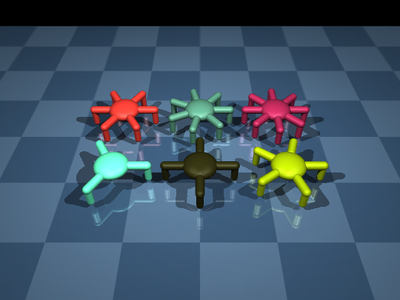

In [42]:
#@title Six Creatures on a floor {vertical-output: true}

arena = mj.MjSpec()

if hasattr(arena, 'compiler'):
  arena.compiler.degree = False  # MuJoCo dev (next release).
else:
  arena.degree = False  # MuJoCo release

# Make arena with textured floor.
chequered = arena.add_texture(
    name="chequered", type=mj.mjtTexture.mjTEXTURE_2D,
    builtin=mj.mjtBuiltin.mjBUILTIN_CHECKER,
    width=300, height=300, rgb1=[.2, .3, .4], rgb2=[.3, .4, .5])
grid = arena.add_material(
    name='grid', texrepeat=[5, 5], reflectance=.2
    ).textures[mj.mjtTextureRole.mjTEXROLE_RGB] = 'chequered'
arena.worldbody.add_geom(
    type=mj.mjtGeom.mjGEOM_PLANE, size=[2, 2, .1], material='grid')
for x in [-2, 2]:
  arena.worldbody.add_light(pos=[x, -1, 3], dir=[-x, 1, -2])

# Instantiate 6 creatures with 3 to 8 legs.
creatures = [make_creature(num_legs=num_legs) for num_legs in range(3, 9)]

# Place them on a grid in the arena.
height = .15
grid = 5 * BODY_RADIUS
xpos, ypos, zpos = np.meshgrid([-grid, 0, grid], [0, grid], [height])
for i, spec in enumerate(creatures):
  # Place spawn sites on a grid.
  spawn_pos = (xpos.flat[i], ypos.flat[i], zpos.flat[i])
  spawn_site = arena.worldbody.add_site(pos=spawn_pos, group=3)
  # Attach to the arena at the spawn sites, with a free joint.
  spawn_body = spawn_site.attach_body(spec.worldbody, '', '-' + str(i))
  spawn_body.add_freejoint()

# Instantiate the physics and render.
model = arena.compile()
render(model)

Multi-legged creatures, ready to roam! Let's inject some controls and watch them move. We'll generate a sinusoidal open-loop control signal of fixed frequency and random phase, recording both video frames and the horizontal positions of the torso geoms, in order to plot the movement trajectories.

In [43]:
#@title Video of the movement {vertical-output: true}

data = mj.MjData(model)
duration = 10   # (Seconds)
framerate = 30  # (Hz)
video = []
pos_x = []
pos_y = []
geoms = arena.worldbody.find_all(mj.mjtObj.mjOBJ_GEOM)
torsos_data = [data.bind(geom) for geom in geoms if 'torso' in geom.name]
torsos_model = [model.bind(geom) for geom in geoms if 'torso' in geom.name]
actuators = [data.bind(actuator) for actuator in arena.actuators]

# Control signal frequency, phase, amplitude.
freq = 5
phase = 2 * np.pi * random_state.rand(len(arena.actuators))
amp = 0.9

# Simulate, saving video frames and torso locations.
mj.mj_resetData(model, data)
with mj.Renderer(model) as renderer:
  while data.time < duration:
    # Inject controls and step the physics.
    for i, actuator in enumerate(actuators):
      actuator.ctrl = amp * np.sin(freq * data.time + phase[i])
    mj.mj_step(model, data)

    # Save torso horizontal positions using name indexing.
    pos_x.append([torso.xpos[0] for torso in torsos_data])
    pos_y.append([torso.xpos[1] for torso in torsos_data])

    # Save video frames.
    if len(video) < data.time * framerate:
      renderer.update_scene(data)
      pixels = renderer.render()
      video.append(pixels.copy())

media.show_video(video, fps=framerate)

This browser does not support the video tag.


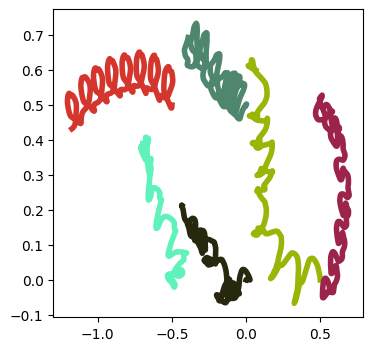

In [44]:
#@title Movement trajectories {vertical-output: true}

creature_colors = [torso.rgba[:3] for torso in torsos_model]
fig, ax = plt.subplots(figsize=(4, 4))
ax.set_prop_cycle(color=creature_colors)
_ = ax.plot(pos_x, pos_y, linewidth=4)

The plot above shows the corresponding movement trajectories of creature positions. Note how `mjSpec` attribute `id` were used to access both `xpos` and `rgba` values. This attribute is valid only after a model is compiled.